# Training a simple CNN: step by step

Training loop for each batch:
`images -> model -> outputs -> loss -> backward (gradients) -> optimizer step`

## 1. Imports


In [1]:
import sys
sys.path.append("../src")

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim

from preprocessing_data import create_dataloaders
from model import SimpleCNN, print_model_summary
from utils import MODELS_DIR, PLOTS_DIR, set_seed, get_device, save_json, plot_training_history

print("torch:", torch.__version__)

torch: 2.14.1


## 2. Hyperparameters


In [2]:
EPOCHS = 5
BATCH_SIZE = 16
LEARNING_RATE = 0.001

## 3. Seed and device

`set_seed` makes the results reproducible. `get_device` should return `mps` on your M2 Mac.

In [3]:
set_seed(42)
device = get_device()
print("Using device:", device)

Using device: mps


## 4. DataLoaders

In [4]:
train_loader, val_loader, _, class_names = create_dataloaders(batch_size=BATCH_SIZE)

print("Train batches:", len(train_loader))
print("Val batches:", len(val_loader))
print("Classes:", class_names)

Sample batch image shape: torch.Size([16, 3, 128, 128])
Sample batch label shape: torch.Size([16])
Class names: ['bibimbap', 'fried_rice']
Train batches: 75
Val batches: 19
Classes: ['bibimbap', 'fried_rice']


## 5. Model

Check the model summary, then send one real batch through the model (forward pass).
Expected output shape: `[batch_size, 2]`. These are **logits**: raw scores, one per class.

In [5]:
model = SimpleCNN(num_classes=2).to(device)
print_model_summary(model)


Model structure:
SimpleCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=32768, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=2, bias=True)
  )
)

Total parameters: 4,199,778
Trainable parameters: 4,199,778


In [6]:
images, labels = next(iter(train_loader))
images = images.to(device)
labels = labels.to(device)

model.eval()
with torch.no_grad():
    outputs = model(images)

print("Images shape:", images.shape)    # [B, 3, 224, 224]
print("Outputs shape:", outputs.shape)  # [B, 2]
print("First 3 logits:\n", outputs[:3])
print("Labels:", labels.tolist())

Images shape: torch.Size([16, 3, 128, 128])
Outputs shape: torch.Size([16, 2])
First 3 logits:
 tensor([[0.0774, 0.1074],
        [0.0632, 0.1055],
        [0.0761, 0.0624]], device='mps:0')
Labels: [1, 0, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 0]


## 6. Loss function: CrossEntropyLoss


In [7]:
criterion = nn.CrossEntropyLoss()

probs = torch.softmax(outputs, dim=1)
true_class_probs = probs[torch.arange(len(labels)), labels]
manual_loss = -torch.log(true_class_probs).mean()

print("Probabilities of first 3 images:\n", probs[:3])
print("Manual loss:   ", manual_loss.item())
print("PyTorch loss:  ", criterion(outputs, labels).item())

Probabilities of first 3 images:
 tensor([[0.4925, 0.5075],
        [0.4894, 0.5106],
        [0.5034, 0.4966]], device='mps:0')
Manual loss:    0.6925370097160339
PyTorch loss:   0.6925370693206787


## 7. Argmax and accuracy

`torch.argmax(outputs, dim=1)` picks the class with the largest logit. Accuracy = correct predictions / total.

In [8]:
predictions = torch.argmax(outputs, dim=1)

print("Predictions:", predictions.tolist())
print("Labels:     ", labels.tolist())
print("Correct:", (predictions == labels).sum().item(), "of", labels.size(0))

Predictions: [1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0]
Labels:      [1, 0, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 0]
Correct: 9 of 16


## 8. One training step by hand

The 5 lines inside the training loop:

1. `optimizer.zero_grad()`: clear old gradients (PyTorch adds new gradients to old ones)
2. `outputs = model(images)`: forward pass
3. `loss = criterion(outputs, labels)`: how wrong we are
4. `loss.backward()`: compute the gradient of the loss for every weight
5. `optimizer.step()`: update the weights (Adam uses the gradients, with learning rate `lr`)

We use a separate test model here, so the real model stays untouched.

In [9]:
test_model = SimpleCNN(num_classes=2).to(device)
test_optimizer = optim.Adam(test_model.parameters(), lr=LEARNING_RATE)

test_model.train()

first_param = next(test_model.parameters())
before = first_param.detach().clone()

test_optimizer.zero_grad()
out = test_model(images)
loss = criterion(out, labels)
print("Loss:", loss.item())

print("Gradient before backward:", first_param.grad)

loss.backward()
print("Gradient norm after backward:", first_param.grad.norm().item())

test_optimizer.step()
print("Weights changed:", not torch.equal(before, first_param.detach()))

Loss: 0.6926476955413818
Gradient before backward: None
Gradient norm after backward: 0.04564807191491127
Weights changed: True


## 9. Sanity check: overfit one batch

A good habit: if the model and the training code are correct, the model must be able to **memorize one small batch**.
The loss should go from about 0.69 down to almost 0.
If it does not, there is a bug in the model or in the training code.

In [10]:
test_model = SimpleCNN(num_classes=2).to(device)
test_optimizer = optim.Adam(test_model.parameters(), lr=LEARNING_RATE)
test_model.train()

for step in range(30):
    test_optimizer.zero_grad()
    out = test_model(images)
    loss = criterion(out, labels)
    loss.backward()
    test_optimizer.step()

    if step % 5 == 0 or step == 29:
        acc = (torch.argmax(out, dim=1) == labels).float().mean().item()
        print(f"step {step:2d} | loss: {loss.item():.4f} | acc: {acc:.2f}")

step  0 | loss: 0.6902 | acc: 0.56
step  5 | loss: 0.2952 | acc: 0.88
step 10 | loss: 0.0147 | acc: 1.00
step 15 | loss: 0.0057 | acc: 1.00
step 20 | loss: 0.0002 | acc: 1.00
step 25 | loss: 0.0003 | acc: 1.00
step 29 | loss: 0.0001 | acc: 1.00


## 10. Epoch functions


In [11]:
def train_one_epoch(model, dataloader, criterion, optimizer, device):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in dataloader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        predictions = torch.argmax(outputs, dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    return epoch_loss, epoch_acc


def validate_one_epoch(model, dataloader, criterion, device):
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in dataloader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)
            predictions = torch.argmax(outputs, dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    return epoch_loss, epoch_acc

## 11. Test validation on an untrained model

Expected: loss close to 0.69 and accuracy close to 0.5 (random guessing between 2 balanced classes).

In [12]:
untrained_model = SimpleCNN(num_classes=2).to(device)
val_loss, val_acc = validate_one_epoch(untrained_model, val_loader, criterion, device)
print(f"Untrained model | Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}")

Untrained model | Val Loss: 0.6925 | Val Acc: 0.5167


## 12. Full training

We create a **fresh** model and optimizer, so the earlier tests do not affect the result.
The best model (by validation accuracy) is saved. A separate file name is used, so the file from `train.py` is not overwritten.

In [ ]:
set_seed(42)

model = SimpleCNN(num_classes=2).to(device)
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": [],
}

best_val_acc = 0.0
MODELS_DIR.mkdir(parents=True, exist_ok=True)
model_save_path = MODELS_DIR / "best_cnn_model.pth"

for epoch in range(EPOCHS):
    train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
    val_loss, val_acc = validate_one_epoch(model, val_loader, criterion, device)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    print(
        f"Epoch [{epoch + 1}/{EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}"
    )

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), model_save_path)
        print(f"Saved new best model to {model_save_path}")

print("\nBest validation accuracy:", round(best_val_acc, 4))

Epoch [1/5] | Train Loss: 0.6131 | Train Acc: 0.7125 | Val Loss: 0.5202 | Val Acc: 0.7400
Saved new best model to /Users/asadbek/Documents/github_projects/korean-food-binary-classifier/outputs/models/best_cnn_model_nb.pth
Epoch [2/5] | Train Loss: 0.4616 | Train Acc: 0.7933 | Val Loss: 0.5415 | Val Acc: 0.7500
Saved new best model to /Users/asadbek/Documents/github_projects/korean-food-binary-classifier/outputs/models/best_cnn_model_nb.pth
Epoch [3/5] | Train Loss: 0.4156 | Train Acc: 0.8158 | Val Loss: 0.4552 | Val Acc: 0.7833
Saved new best model to /Users/asadbek/Documents/github_projects/korean-food-binary-classifier/outputs/models/best_cnn_model_nb.pth
Epoch [4/5] | Train Loss: 0.3719 | Train Acc: 0.8292 | Val Loss: 0.4461 | Val Acc: 0.7767
Epoch [5/5] | Train Loss: 0.3495 | Train Acc: 0.8575 | Val Loss: 0.4646 | Val Acc: 0.7867
Saved new best model to /Users/asadbek/Documents/github_projects/korean-food-binary-classifier/outputs/models/best_cnn_model_nb.pth

Best validation accur

## 13. Training curves

How to read them:
- both losses go down: the model is learning
- train loss goes down but val loss goes up: **overfitting** (the model memorizes train images)
- both stay high: **underfitting** (the model is too simple or the learning rate is not suitable)

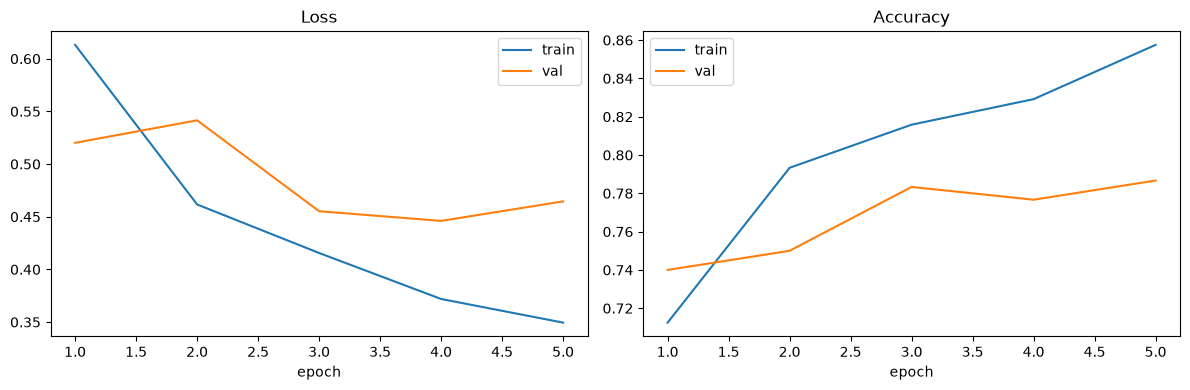

In [14]:
epochs_range = range(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs_range, history["train_loss"], label="train")
axes[0].plot(epochs_range, history["val_loss"], label="val")
axes[0].set_title("Loss")
axes[0].set_xlabel("epoch")
axes[0].legend()

axes[1].plot(epochs_range, history["train_acc"], label="train")
axes[1].plot(epochs_range, history["val_acc"], label="val")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

## 14. Save history, class names and plot

The same helper functions that `train.py` uses.

In [ ]:
save_json(history, PLOTS_DIR / "training_history.json")
save_json(class_names, MODELS_DIR / "class_names.json")
plot_training_history(history, PLOTS_DIR / "training_curves.png")

print("Saved history, class names and plot.")

Saved history, class names and plot.


## 15. Load the saved best model

Check that the saved file works: load it into a new model and evaluate on validation data.
The validation accuracy must be the same as `best_val_acc`.

In [16]:
loaded_model = SimpleCNN(num_classes=2).to(device)
loaded_model.load_state_dict(torch.load(model_save_path, map_location=device))

val_loss, val_acc = validate_one_epoch(loaded_model, val_loader, criterion, device)
print(f"Loaded model | Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}")
print("Best val acc during training:", round(best_val_acc, 4))

Loaded model | Val Loss: 0.4646 | Val Acc: 0.7867
Best val acc during training: 0.7867
